Data shape  : (993, 300, 300, 3)
Labels shape: (993,)
Classes     : ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']

Train : (694, 300, 300, 3), (694,)
Val   : (100, 300, 300, 3),   (100,)
Test  : (199, 300, 300, 3),  (199,)


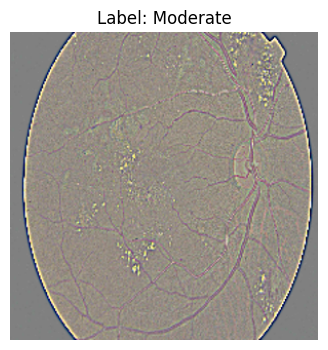

In [2]:
import numpy as np
import pickle
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
# ============================================================
# LOAD
# ============================================================
with open("../../data/processed/sample_200/sample_dataset.pkl", 'rb') as f:
    dataset = pickle.load(f)

data        = dataset['data']         # (N, 300, 300, 3) uint8
labels      = dataset['labels']       # (N,) int
class_names = dataset['class_names']  # ['Mild', 'Moderate', ...]

print(f"Data shape  : {data.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Classes     : {class_names}")

# ============================================================
# CHIA TRAIN / VAL / TEST
# ============================================================
x_trainval, x_test, y_trainval, y_test = train_test_split(
    data, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval,
    test_size=0.125,  # 0.125 * 0.8 = 0.1 tổng → 70/10/20
    random_state=42,
    stratify=y_trainval
)

print(f"\nTrain : {x_train.shape}, {y_train.shape}")
print(f"Val   : {x_val.shape},   {y_val.shape}")
print(f"Test  : {x_test.shape},  {y_test.shape}")

# ============================================================
# NORMALIZE (làm ngay trước khi train)
# ============================================================
x_train = x_train.astype('float32') / 255.0
x_val   = x_val.astype('float32')   / 255.0
x_test  = x_test.astype('float32')  / 255.0

img = x_train[0]  # shape (300, 300, 3), float32 0-1

# Nếu đã normalize thì convert lại để hiển thị
# img = (img * 255).astype('uint8')  # bỏ comment nếu cần

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f"Label: {class_names[y_train[0]]}")
plt.axis('off')
plt.show()